# 01 - Teacher & Student baseline

In [ ]:
import sys; sys.path.append("..")
%load_ext autoreload
%autoreload 2

import torch
import matplotlib.pyplot as plt
from src.data import get_dataloaders
from src.models import build_model
from src.metrics import count_parameters, model_size_mb, save_result
from src.train import get_device, init_weights, fit, evaluate, overfit_one_batch

device = get_device()
torch.backends.cudnn.benchmark = True

train_loader, val_loader, test_loader = get_dataloaders("../data", batch_size=128)

Device: cpu


In [2]:
# Sanity check: overfit su un solo batch (train) per verificare che la loss scenda  (e il training quindi funzioni)
for name in ["teacher", "student"]:
    torch.manual_seed(0)
    m = build_model(name)
    init_weights(m)
    print(f"--- {name} ---")
    overfit_one_batch(m, train_loader, device)

--- teacher ---


c:\Users\Pietr\Desktop\Model-Compression\.venv\lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


step   0 | loss 2.5312
step  20 | loss 0.0962
step  40 | loss 0.0061
step  60 | loss 0.0045
step  80 | loss 0.0004
step  99 | loss 0.0004
--- student ---
step   0 | loss 2.3111
step  20 | loss 1.6453
step  40 | loss 0.1680
step  60 | loss 0.0341
step  80 | loss 0.0128
step  99 | loss 0.0077


In [ ]:
# Baseline training: traina il modello per x epoche, salva il miglior checkpoint sul validation set e registra i risultati in checkpoints e results.json
# funzioni helper per evitare replicazione codice
def run_baseline(name, epochs=30):
    torch.manual_seed(0)
    model = build_model(name)
    init_weights(model)
    model.to(device)

    history, train_time = fit(model, train_loader, val_loader, device, epochs=epochs,
                              ckpt_path=f"../checkpoints/{name}_baseline.pt")

    _, val_acc = evaluate(model, val_loader, device)
    _, test_acc = evaluate(model, test_loader, device)
    c = count_parameters(model)
    print(f"\n{name}: val {val_acc * 100:.2f}% | test {test_acc * 100:.2f}% | "
          f"{c['total']:,} params | {model_size_mb(model):.2f} MB | {train_time / 60:.1f} min")

    save_result(f"{name}_baseline", val_acc=val_acc, test_acc=test_acc,
                params=c["total"], size_mb=model_size_mb(model),
                train_time_s=train_time, epochs=epochs)
    return model, history

In [ ]:
# Addestramento del teacher
teacher, h_teacher = run_baseline("teacher",epochs=30)

ep   1/2 | train loss 2.238 acc 16.01 | val loss 1.982 acc 20.74 (best 20.74) | lr 0.0500
ep   2/2 | train loss 1.891 acc 25.07 | val loss 1.827 acc 28.80 (best 28.80) | lr 0.0250

teacher: val 28.80% | test 29.48% | 15,530,762 params | 62.17 MB | 8.7 min


In [ ]:
# Addestramento dello student
student, h_student = run_baseline("student",epochs=30)

ep   1/2 | train loss 1.711 acc 35.98 | val loss 1.406 acc 48.20 (best 48.20) | lr 0.0500
ep   2/2 | train loss 1.341 acc 52.01 | val loss 1.280 acc 53.22 (best 53.22) | lr 0.0250

student: val 53.22% | test 52.91% | 245,226 params | 1.00 MB | 0.9 min


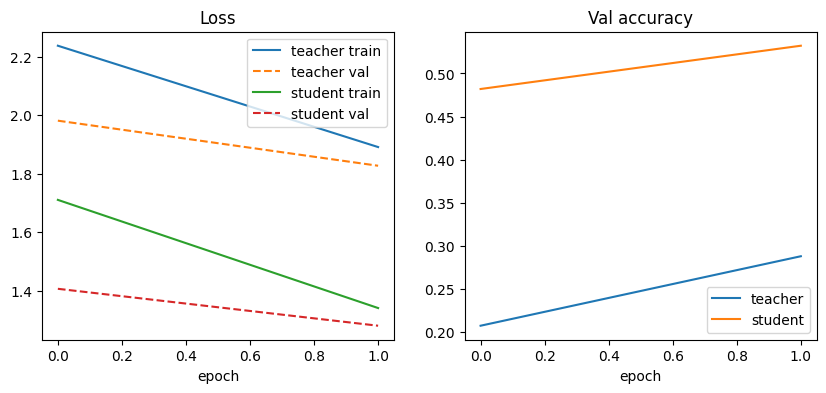

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for name, h in [("teacher", h_teacher), ("student", h_student)]:
    ax[0].plot(h["train_loss"], label=f"{name} train")
    ax[0].plot(h["val_loss"], "--", label=f"{name} val")
    ax[1].plot(h["val_acc"], label=name)
ax[0].set_title("Loss"); ax[0].legend()
ax[1].set_title("Val accuracy"); ax[1].legend()
for a in ax: a.set_xlabel("epoch")
plt.show()

In [ ]:
# Per ricaricare il modello salvato e valutarlo senza rifare il training
import importlib, src.metrics
importlib.reload(src.metrics)   # con %autoreload 2 di solito basta il salvataggio, ma così sei sicuro
from src.metrics import count_parameters, model_size_mb, save_result

teacher = build_model("teacher").to(device)
teacher.load_state_dict(torch.load("../checkpoints/teacher_baseline.pt", map_location=device))

_, val_acc = evaluate(teacher, val_loader, device)
_, test_acc = evaluate(teacher, test_loader, device)
c = count_parameters(teacher)
print(f"val {val_acc * 100:.2f}% | test {test_acc * 100:.2f}% | "
      f"{c['total']:,} params | {model_size_mb(teacher):.2f} MB")

val 28.80% | test 29.48% | 15,530,762 params | 62.17 MB
